# 1 · Preprocessing Dataset – Klasifikasi Latihan Otot Punggung

Notebook ini menjalankan seluruh tahap preprocessing sesuai Bab III proposal:

| Tahap | Isi | Output |
|---|---|---|
| 0 | Setup & konfigurasi | – |
| 1 | Audit dataset | `data/metadata.csv`, `qa/first_frames/` |
| 2 | Ekstraksi keypoints (MediaPipe BlazePose) | `data/keypoints_raw/` |
| 3 | Pembersihan (interpolasi frame hilang) | `data/keypoints_clean/`, `qa/missing_report.csv` |
| 3b | Visualisasi marking keypoints | `qa/overlay/`, `qa/snapshots/` |
| 4 | Ekstraksi fitur Skema A & Skema B | `data/features/` |
| 5 | Split data per subjek | `data/splits.json` |
| 6 | Augmentasi data ×3 (dataset terpisah) | `data/dataset_augmentasi/`, `qa/augmented/` |

Setiap tahap menyimpan hasilnya ke file, jadi kalau ada yang perlu diulang cukup jalankan ulang dari tahap tersebut (tidak perlu menjalankan MediaPipe lagi).

**Kernel:** pilih **Python (TA Albert)** (venv `.venv`, Python 3.11, MediaPipe 0.10.35).

**Urutan notebook:** `1_preprocessing.ipynb` → `2_training_tanpa_augmentasi.ipynb` → `3_training_dengan_augmentasi.ipynb`.

## Tahap 0 – Setup

Environment sudah disiapkan dengan:
```bash
brew install python@3.11
python3.11 -m venv .venv
.venv/bin/pip install "mediapipe<1" opencv-python numpy pandas scipy tqdm matplotlib ipykernel ipywidgets
```
> MediaPipe 1.0.x crash di macOS (bug GPU Metal), karena itu dipakai seri 0.10.x.

Model pose: `models/pose_landmarker_full.task`.

**💡 Penjelasan kode**

- `import ...` memuat library yang dipakai: **OpenCV (`cv2`)** untuk membaca video, **MediaPipe** untuk deteksi pose, **NumPy/Pandas** untuk mengolah angka dan tabel, **Matplotlib** untuk grafik, **tqdm** untuk progress bar.
- `GLOG_minloglevel = 2` hanya meredam pesan log MediaPipe yang tidak penting.
- Baris terakhir mencetak versi library, berguna untuk ditulis di Bab IV (lingkungan pengujian).

In [2]:
import os
os.environ.setdefault("GLOG_minloglevel", "2")  # redam log C++ MediaPipe

import hashlib
import json
import re
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from IPython.display import Video, display
from mediapipe.tasks.python import BaseOptions, vision
from scipy.signal import savgol_filter
from tqdm.auto import tqdm

print("mediapipe", mp.__version__, "| opencv", cv2.__version__, "| numpy", np.__version__)

mediapipe 0.10.35 | opencv 5.0.0 | numpy 2.4.6


### Konfigurasi

Semua angka yang dikutip di Bab III ada di sini.

**💡 Penjelasan kode**

Sel ini berisi **semua pengaturan** di satu tempat, jadi jika ingin mengubah sesuatu cukup di sini:
- **Path**: lokasi folder dataset, hasil, dan model MediaPipe. `Path.cwd()` = folder tempat notebook ini berada.
- `CLASS_MAP`: nama kelas → angka label (0, 1, 2). Model hanya mengenal angka.
- `TARGET_W, TARGET_H, TARGET_FPS`: semua video diseragamkan ke 720×1280 dan 30 FPS.
- `VIS_THRESHOLD`, `MAX_MISSING_RATIO`: batas untuk pembersihan data (Tahap 3).
- `LANDMARK_NAMES`: 33 titik tubuh keluaran MediaPipe. `KEYPOINTS`: 13 titik yang dipakai (Tabel 3.2).
- `ANGLES`: 8 sudut sendi (Tabel 3.3). Contoh `(23, 11, 13)` = sudut di bahu kiri (11), dibentuk oleh pinggul kiri (23) dan siku kiri (13).
- `SKELETON_13/33`: pasangan titik yang dihubungkan garis saat visualisasi.
- `SEED`: angka acak tetap supaya hasil selalu sama. `SUBJECT_GROUPS`: subjek 8 & 9 digabung karena ada file kembar.

In [25]:
# ---------------- Path ----------------
ROOT = Path.cwd()
RAW_DIR = ROOT / "raw_dataset"
DATA_DIR = ROOT / "data"
QA_DIR = ROOT / "qa"
MODEL_PATH = ROOT / "models" / "pose_landmarker_full.task"

METADATA_CSV = DATA_DIR / "metadata.csv"
KP_RAW_DIR = DATA_DIR / "keypoints_raw"
KP_CLEAN_DIR = DATA_DIR / "keypoints_clean"
FEAT_DIR = DATA_DIR / "features"
SPLITS_JSON = DATA_DIR / "splits.json"

# Isi angka (mis. 2) untuk uji coba cepat: hanya N video pertama per kelas.
SUBSET = None

# ---------------- Kelas ----------------
CLASS_MAP = {"Lat_Pulldown": 0, "Seated_Cable_Row": 1, "Bent_over": 2}

# ---------------- Standarisasi video ----------------
TARGET_W, TARGET_H = 720, 1280   # portrait, rasio 9:16 sama dengan video asli
TARGET_FPS = 30

# ---------------- Pembersihan ----------------
VIS_THRESHOLD = 0.5       # di bawah ini keypoint dianggap "visibility rendah"
MAX_MISSING_RATIO = 0.2   # video dengan >20% frame tak terdeteksi di-exclude
SMOOTHING = False         # Savitzky-Golay; default mati agar Skema A tetap "mentah"
SMOOTH_WINDOW, SMOOTH_POLY = 5, 2

# ---------------- MediaPipe BlazePose: 33 landmark ----------------
LANDMARK_NAMES = [
    "nose", "left_eye_inner", "left_eye", "left_eye_outer", "right_eye_inner",
    "right_eye", "right_eye_outer", "left_ear", "right_ear", "mouth_left",
    "mouth_right", "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_pinky", "right_pinky", "left_index",
    "right_index", "left_thumb", "right_thumb", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle", "left_heel",
    "right_heel", "left_foot_index", "right_foot_index",
]

# 13 keypoints terpilih (Tabel 3.2)
KEYPOINTS = [0, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]

# 8 sudut persendian (Tabel 3.3): nama -> (A, B, C), B = sendi yang diukur
ANGLES = {
    "left_shoulder_angle":  (23, 11, 13),
    "right_shoulder_angle": (24, 12, 14),
    "left_elbow_angle":     (11, 13, 15),
    "right_elbow_angle":    (12, 14, 16),
    "left_hip_angle":       (11, 23, 25),
    "right_hip_angle":      (12, 24, 26),
    "left_knee_angle":      (23, 25, 27),
    "right_knee_angle":     (24, 26, 28),
}

# Garis kerangka untuk visualisasi
SKELETON_13 = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24),
               (23, 24), (23, 25), (25, 27), (24, 26), (26, 28)]
SKELETON_33 = SKELETON_13 + [
    (0, 1), (1, 2), (2, 3), (3, 7), (0, 4), (4, 5), (5, 6), (6, 8), (9, 10),
    (15, 17), (15, 19), (15, 21), (17, 19), (16, 18), (16, 20), (16, 22), (18, 20),
    (27, 29), (29, 31), (27, 31), (28, 30), (30, 32), (28, 32),
]

# ---------------- Split ----------------
SEED = 42
# Subjek yang harus selalu di split yang sama (lpd8_08 dan lpd9_08 file identik).
SUBJECT_GROUPS = [[8, 9]]

### Fungsi bantu

**💡 Penjelasan kode**

Fungsi-fungsi bantu yang dipakai berulang kali:
- `list_videos()`: menelusuri folder `raw_dataset`, lalu membaca kelas, nomor subjek, dan nomor repetisi dari nama file (contoh `lpd3_05` → subjek 3, repetisi 5) memakai *regular expression*.
- `frame_step(fps)`: video 60 FPS diambil setiap 2 frame supaya menjadi 30 FPS.
- `read_frames(path)`: membaca video frame demi frame, menurunkan FPS, dan mengubah ukuran ke 720×1280. Memakai `yield` (generator) supaya tidak semua frame dimuat ke memori sekaligus.
- `make_landmarker()`: membuat detektor pose MediaPipe mode **VIDEO** (memanfaatkan frame sebelumnya sehingga lebih stabil).
- `joint_angles(...)`: menghitung sudut sendi. Vektor BA dan BC dibentuk dari titik sendi B, lalu sudut antara keduanya dihitung dengan `arctan2`. Koordinat diubah ke piksel dulu, karena x dan y MediaPipe dinormalisasi terhadap lebar dan tinggi yang berbeda.
- `npz_path(...)`: menentukan lokasi file hasil per video.

In [27]:
_VIDEO_RE = re.compile(r"^[a-z]+(\d+)_(\d+)$")


def list_videos():
    # Daftar semua video (dict), urut per kelas/subjek/rep.
    videos = []
    for cls in CLASS_MAP:
        paths = sorted((RAW_DIR / cls).glob("*/*.mp4"))
        for path in paths[:SUBSET] if SUBSET else paths:
            m = _VIDEO_RE.match(path.stem)
            if m is None:
                raise ValueError(f"Nama file tidak sesuai pola: {path}")
            videos.append({"video_id": path.stem, "class": cls, "label": CLASS_MAP[cls],
                           "subject": int(m.group(1)), "rep": int(m.group(2)), "path": path})
    return videos


VIDEOS = list_videos()
VIDEO_BY_ID = {v["video_id"]: v for v in VIDEOS}


def frame_step(src_fps):
    # Ambil 1 dari tiap `step` frame agar FPS mendekati TARGET_FPS (60 FPS -> step 2).
    return max(1, round(src_fps / TARGET_FPS)) if src_fps > 0 else 1


def read_frames(path):
    # Generator frame BGR yang sudah distandarisasi (FPS & resolusi).
    cap = cv2.VideoCapture(str(path))
    step = frame_step(cap.get(cv2.CAP_PROP_FPS))
    i = 0
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            if i % step == 0:
                yield cv2.resize(frame, (TARGET_W, TARGET_H), interpolation=cv2.INTER_AREA)
            i += 1
    finally:
        cap.release()


def make_landmarker():
    # PoseLandmarker baru dalam mode VIDEO (satu instance per video).
    options = vision.PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1,
    )
    return vision.PoseLandmarker.create_from_options(options)


def joint_angles(landmarks, triplets):
    # Sudut sendi (derajat, 0-180) per frame dari landmarks (T, 33, >=2).
    # Koordinat dikonversi ke piksel dulu: x dan y MediaPipe dinormalisasi terhadap
    # lebar (720) dan tinggi (1280) yang berbeda, tanpa ini sudut terdistorsi.
    xy = landmarks[..., :2] * np.array([TARGET_W, TARGET_H])
    out = np.empty((len(landmarks), len(triplets)), dtype=np.float32)
    for j, (a, b, c) in enumerate(triplets):
        ba, bc = xy[:, a] - xy[:, b], xy[:, c] - xy[:, b]
        rad = np.arctan2(bc[:, 1], bc[:, 0]) - np.arctan2(ba[:, 1], ba[:, 0])
        deg = np.abs(np.degrees(rad)) % 360
        out[:, j] = np.where(deg > 180, 360 - deg, deg)
    return out


def npz_path(root, v):
    return root / v["class"] / f"{v['video_id']}.npz"


print(f"{len(VIDEOS)} video ditemukan")

240 video ditemukan


## Tahap 1 – Audit Dataset

Mendata setiap video: resolusi, FPS, jumlah frame, durasi, dan hash md5 (untuk mendeteksi file kembar). Frame pertama tiap video disusun menjadi grid untuk mengecek orientasi.

**💡 Penjelasan kode**

- `md5(path)`: membuat "sidik jari" isi file. Dua file dengan md5 sama berarti **isinya identik** (file kembar).
- `contact_sheet(...)`: menyusun frame pertama semua video menjadi satu gambar grid.
- Loop `for v in VIDEOS`: membuka setiap video, mencatat resolusi, FPS, jumlah frame, durasi, dan md5, lalu mengambil frame pertamanya.
- `duplicate_of`: jika md5 sebuah video sama dengan video sebelumnya, nama video pertama dicatat di sini.
- Hasil disimpan ke `data/metadata.csv` dan `qa/first_frames/`.

In [28]:
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()


def contact_sheet(frames, labels, cols=10, thumb_w=108):
    thumb_h = int(thumb_w * 16 / 9)
    rows = -(-len(frames) // cols)
    sheet = np.full((rows * thumb_h, cols * thumb_w, 3), 255, np.uint8)
    for i, (frame, label) in enumerate(zip(frames, labels)):
        r, c = divmod(i, cols)
        t = cv2.resize(frame, (thumb_w, thumb_h), interpolation=cv2.INTER_AREA)
        cv2.putText(t, label, (3, 12), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (0, 0, 255), 1)
        sheet[r * thumb_h:(r + 1) * thumb_h, c * thumb_w:(c + 1) * thumb_w] = t
    return sheet


rows, thumbs = [], {cls: ([], []) for cls in CLASS_MAP}
for v in tqdm(VIDEOS, desc="Audit"):
    cap = cv2.VideoCapture(str(v["path"]))
    fps = cap.get(cv2.CAP_PROP_FPS)
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"Tidak bisa membaca {v['path']}")
    h, w = frame.shape[:2]  # ukuran setelah rotasi diterapkan OpenCV
    rows.append({
        "video_id": v["video_id"], "class": v["class"], "label": v["label"],
        "subject": v["subject"], "rep": v["rep"], "path": str(v["path"].relative_to(ROOT)),
        "width": w, "height": h, "orientation": "portrait" if h > w else "landscape",
        "fps": round(fps, 2), "n_frames": n_frames,
        "duration_s": round(n_frames / fps, 3) if fps else None,
        "frames_after_std": -(-n_frames // frame_step(fps)),
        "md5": md5(v["path"]),
    })
    thumbs[v["class"]][0].append(frame)
    thumbs[v["class"]][1].append(v["video_id"])

meta = pd.DataFrame(rows)
first = meta.groupby("md5")["video_id"].transform("first")
meta["duplicate_of"] = np.where(first != meta["video_id"], first, "")

DATA_DIR.mkdir(parents=True, exist_ok=True)
meta.to_csv(METADATA_CSV, index=False)

(QA_DIR / "first_frames").mkdir(parents=True, exist_ok=True)
for cls, (frames, labels) in thumbs.items():
    cv2.imwrite(str(QA_DIR / "first_frames" / f"{cls}.jpg"), contact_sheet(frames, labels))

print(f"Tersimpan: {METADATA_CSV}")
meta.head()

Audit:   0%|          | 0/240 [00:00<?, ?it/s]

Tersimpan: /Users/albobchai/Desktop/Tugas Akhir - Albert/data/metadata.csv


,video_id,class,label,subject,rep,path,width,height,orientation,fps,n_frames,duration_s,frames_after_std,md5,duplicate_of
0,lpd1_01,Lat_Pulldown,0,1,1,raw_dataset/Lat_Pulldown/lpd_01/lpd1_01.mp4,1080,1920,portrait,30.0,89,2.967,89,1c259273871e36ef12237b988acfae56,
1,lpd1_02,Lat_Pulldown,0,1,2,raw_dataset/Lat_Pulldown/lpd_01/lpd1_02.mp4,1080,1920,portrait,30.0,82,2.733,82,e4e6410570c705d209f0e2a8b92d42c1,
2,lpd1_03,Lat_Pulldown,0,1,3,raw_dataset/Lat_Pulldown/lpd_01/lpd1_03.mp4,1080,1920,portrait,30.0,90,3.000,90,3a305f53a7dded6f173d4d051934571d,
3,lpd1_04,Lat_Pulldown,0,1,4,raw_dataset/Lat_Pulldown/lpd_01/lpd1_04.mp4,1080,1920,portrait,30.0,85,2.833,85,9a9a4dd740c9c6aac444699c459f2d32,
4,lpd1_05,Lat_Pulldown,0,1,5,raw_dataset/Lat_Pulldown/lpd_01/lpd1_05.mp4,1080,1920,portrait,30.0,90,3.000,90,e58c5a927c03eebcaf2d4d3b0124475c,


**💡 Penjelasan kode**

Merangkum tabel audit dengan `groupby`: jumlah video per kelas, variasi resolusi, FPS, orientasi, durasi, dan daftar file kembar. Hasil ini menjadi bahan deskripsi dataset di Bab IV.

In [29]:
print("Jumlah per kelas:\n" + meta.groupby("class").size().to_string(), "\n")
print("Resolusi:\n" + meta.groupby(["width", "height"]).size().to_string(), "\n")
print("FPS:\n" + meta.groupby("fps").size().to_string(), "\n")
print("Orientasi:\n" + meta.groupby("orientation").size().to_string(), "\n")
print("Video 60 FPS:", ", ".join(meta.loc[meta.fps > 45, "video_id"]) or "-", "\n")
print("Durasi (detik) per kelas:")
print(meta.groupby("class")["duration_s"].describe()[["min", "mean", "max"]].round(2).to_string(), "\n")
dups = meta[meta.duplicate_of != ""]
print(f"File duplikat: {len(dups)}")
for _, r in dups.iterrows():
    print(f"  {r.video_id} == {r.duplicate_of}")

Jumlah per kelas:
class
Bent_over           80
Lat_Pulldown        80
Seated_Cable_Row    80 

Resolusi:
width  height
1080   1920      234
2160   3840        6 

FPS:
fps
30.0    224
60.0     16 

Orientasi:
orientation
portrait    240 

Video 60 FPS: scr9_01, scr9_02, scr9_03, scr9_04, scr9_05, scr9_06, scr9_07, scr9_08, bor6_01, bor6_02, bor6_03, bor6_04, bor6_05, bor6_06, bor6_07, bor6_08 

Durasi (detik) per kelas:
                  min  mean   max
class                            
Bent_over         2.0  2.39  2.93
Lat_Pulldown      1.9  2.68  3.33
Seated_Cable_Row  2.0  2.56  3.27 

File duplikat: 4
  lpd3_05 == lpd3_04
  lpd5_07 == lpd5_01
  lpd9_08 == lpd8_08
  bor4_08 == bor4_05


**💡 Penjelasan kode**

Menampilkan grid frame pertama yang tadi disimpan, untuk mengecek secara visual bahwa orientasi video benar (tidak terbalik) dan melihat sudut kamera tiap kelas.

In [30]:
# Grid frame pertama per kelas (cek orientasi & sudut kamera)
fig, axes = plt.subplots(1, 3, figsize=(18, 9))
for ax, cls in zip(axes, CLASS_MAP):
    ax.imshow(cv2.cvtColor(cv2.imread(str(QA_DIR / "first_frames" / f"{cls}.jpg")), cv2.COLOR_BGR2RGB))
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Tahap 2 – Ekstraksi Keypoints (MediaPipe BlazePose)

Untuk setiap video: standarisasi (30 FPS, 720×1280, BGR→RGB), lalu deteksi pose per frame dalam mode VIDEO (memakai informasi frame sebelumnya sehingga lebih stabil). **Semua 33 landmark** disimpan supaya feature selection bisa diubah tanpa menjalankan MediaPipe lagi.

Output per video `data/keypoints_raw/<kelas>/<video_id>.npz`:
- `landmarks` (T, 33, 4): x, y, z, visibility; `NaN` jika pose tidak terdeteksi
- `detected` (T,): apakah pose terdeteksi di frame tersebut

Video yang sudah diekstrak akan dilewati. Set `OVERWRITE = True` untuk mengulang.

**💡 Penjelasan kode**

Inti Tahap 2:
- `extract_keypoints(path)`: untuk setiap frame, gambar diubah dari BGR (format OpenCV) ke RGB (format MediaPipe), lalu `detect_for_video` mendeteksi 33 titik tubuh. Setiap titik punya **x, y** (posisi 0–1 relatif terhadap lebar/tinggi gambar), **z** (perkiraan kedalaman), dan **visibility** (keyakinan titik terlihat, 0–1).
- Jika pose tidak terdeteksi, frame diisi `NaN` dan ditandai `detected = False`.
- Hasil tiap video disimpan ke `.npz` (format NumPy terkompresi). Video yang sudah punya file akan **dilewati**, jadi menjalankan ulang sel ini cepat. Proses MediaPipe hanya berat saat pertama kali.

In [8]:
OVERWRITE = False


def extract_keypoints(path):
    landmarker = make_landmarker()
    landmarks, detected = [], []
    for i, frame in enumerate(read_frames(path)):
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        result = landmarker.detect_for_video(image, int(i * 1000 / TARGET_FPS))
        if result.pose_landmarks:
            landmarks.append([[p.x, p.y, p.z, p.visibility] for p in result.pose_landmarks[0]])
            detected.append(True)
        else:
            landmarks.append(np.full((33, 4), np.nan))
            detected.append(False)
    landmarker.close()
    return np.asarray(landmarks, np.float32), np.asarray(detected, bool)


n_done = 0
for v in tqdm(VIDEOS, desc="Ekstraksi"):
    out = npz_path(KP_RAW_DIR, v)
    if out.exists() and not OVERWRITE:
        continue
    landmarks, detected = extract_keypoints(v["path"])
    out.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out, landmarks=landmarks, detected=detected)
    n_done += 1
print(f"{n_done} video diekstrak, {len(VIDEOS) - n_done} dilewati (sudah ada).")

Ekstraksi:   0%|          | 0/240 [00:00<?, ?it/s]

0 video diekstrak, 240 dilewati (sudah ada).


**💡 Penjelasan kode**

Menghitung persentase frame yang berhasil dideteksi MediaPipe per kelas. Nilai mendekati 1,0 berarti pose hampir selalu terdeteksi.

In [9]:
# Ringkasan tingkat deteksi per kelas
det_rows = []
for v in VIDEOS:
    d = np.load(npz_path(KP_RAW_DIR, v))["detected"]
    det_rows.append({"class": v["class"], "video_id": v["video_id"], "n_frames": len(d), "detect_rate": d.mean()})
det_df = pd.DataFrame(det_rows)
print(det_df.groupby("class").agg(videos=("video_id", "count"), mean_frames=("n_frames", "mean"),
                                  mean_detect=("detect_rate", "mean"), min_detect=("detect_rate", "min")).round(3))

                  videos  mean_frames  mean_detect  min_detect
class                                                         
Bent_over             80       71.725          1.0         1.0
Lat_Pulldown          80       80.388          1.0         1.0
Seated_Cable_Row      80       76.912          1.0         1.0


## Tahap 3 – Pembersihan

- Frame tanpa deteksi pose **tidak dibuang** (supaya urutan waktu tidak loncat), tetapi diisi dengan **interpolasi linear** dari frame sebelum dan sesudahnya. Frame di awal/akhir memakai nilai terdekat.
- Video dengan lebih dari `MAX_MISSING_RATIO` (20%) frame hilang ditandai `excluded`.
- Keypoint dengan visibility < `VIS_THRESHOLD` ditandai `lowvis` (nilainya tetap dipakai, hanya dicatat untuk laporan & visualisasi).
- `SMOOTHING` opsional (default mati).

Output per video `data/keypoints_clean/<kelas>/<video_id>.npz`: `landmarks`, `interpolated` (T,), `lowvis` (T, 33), `excluded`.

**💡 Penjelasan kode**

- `clean(...)`: frame yang posenya tidak terdeteksi diisi dengan **interpolasi linear** (`np.interp`), yaitu garis lurus antara nilai frame sebelum dan sesudahnya. Frame tidak dibuang supaya urutan waktu tidak meloncat.
- Video dengan lebih dari 20% frame hilang ditandai `excluded` (tidak dipakai).
- `lowvis`: titik dengan visibility < 0,5 dicatat (nilainya tetap dipakai).
- Loop di bawahnya menjalankan `clean` untuk semua video, menyimpan hasil ke `data/keypoints_clean/`, dan membuat laporan `qa/missing_report.csv`.

In [10]:
def clean(landmarks, detected):
    T = len(landmarks)
    missing_ratio = 1 - detected.mean()
    excluded = missing_ratio > MAX_MISSING_RATIO or detected.sum() < 2
    lm = landmarks.copy()
    if not excluded and not detected.all():
        t, idx = np.arange(T), np.flatnonzero(detected)
        flat = lm.reshape(T, -1)
        for j in range(flat.shape[1]):
            flat[:, j] = np.interp(t, idx, flat[idx, j])
        lm = flat.reshape(T, 33, 4)
    if SMOOTHING and not excluded and T >= SMOOTH_WINDOW:
        lm[..., :3] = savgol_filter(lm[..., :3], SMOOTH_WINDOW, SMOOTH_POLY, axis=0)
    lowvis = np.nan_to_num(lm[..., 3], nan=0.0) < VIS_THRESHOLD
    return lm, ~detected, lowvis, excluded, missing_ratio


report = []
for v in tqdm(VIDEOS, desc="Pembersihan"):
    raw = np.load(npz_path(KP_RAW_DIR, v))
    lm, interpolated, lowvis, excluded, missing_ratio = clean(raw["landmarks"], raw["detected"])
    out = npz_path(KP_CLEAN_DIR, v)
    out.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out, landmarks=lm, interpolated=interpolated, lowvis=lowvis, excluded=excluded)
    row = {"video_id": v["video_id"], "class": v["class"], "subject": v["subject"],
           "n_frames": len(lm), "missing_ratio": round(missing_ratio, 4), "excluded": excluded}
    for k in KEYPOINTS:  # proporsi frame dengan visibility rendah per keypoint
        row[f"lowvis_{LANDMARK_NAMES[k]}"] = round(lowvis[:, k].mean(), 4)
    report.append(row)

report = pd.DataFrame(report)
QA_DIR.mkdir(parents=True, exist_ok=True)
report.to_csv(QA_DIR / "missing_report.csv", index=False)

print(f"Video di-exclude: {int(report.excluded.sum())}")
print(report[report.excluded][["video_id", "missing_ratio"]].to_string(index=False) if report.excluded.any() else "")
print("\nRata-rata frame hilang per kelas:")
print(report.groupby("class")["missing_ratio"].agg(["mean", "max"]).round(4))

Pembersihan:   0%|          | 0/240 [00:00<?, ?it/s]

Video di-exclude: 0


Rata-rata frame hilang per kelas:
                  mean  max
class                      
Bent_over          0.0  0.0
Lat_Pulldown       0.0  0.0
Seated_Cable_Row   0.0  0.0


**💡 Penjelasan kode**

Membuat *heatmap*: baris = keypoint, kolom = kelas, warna = seberapa sering titik itu kurang terlihat. Titik yang sering merah berarti sering tertutup dari sudut kamera kelas itu, misalnya lutut pada subjek 10.

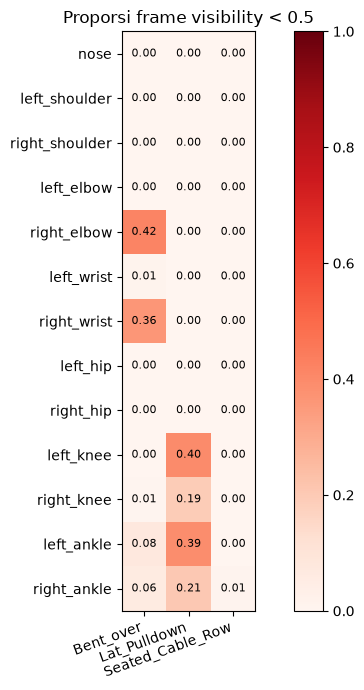

In [11]:
# Proporsi frame dengan visibility rendah per keypoint per kelas.
# Nilai tinggi = keypoint sering tertutup / tidak terlihat dari sudut kamera kelas tersebut.
lowvis_cols = [c for c in report.columns if c.startswith("lowvis_")]
lv = report.groupby("class")[lowvis_cols].mean().T
lv.index = [c.removeprefix("lowvis_") for c in lv.index]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(lv.values, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(lv.columns)), lv.columns, rotation=20, ha="right")
ax.set_yticks(range(len(lv.index)), lv.index)
for i in range(lv.shape[0]):
    for j in range(lv.shape[1]):
        ax.text(j, i, f"{lv.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Proporsi frame visibility < %.1f" % VIS_THRESHOLD)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Tahap 3b – Visualisasi Marking Keypoints

Menggambar di atas video:
1. **13 keypoints terpilih** (atau semua 33 dengan `all33=True`) beserta namanya
2. **Garis kerangka**
3. **Nilai sudut (Skema B)** di samping sendinya, memakai fungsi `joint_angles` yang sama dengan Tahap 4, jadi angka yang tampil **persis sama** dengan yang masuk ke model
4. **Warna titik:** 🟢 hijau = terdeteksi jelas, 🟡 kuning = visibility rendah, 🔴 merah = hasil interpolasi
5. **Info:** kelas, nama video, nomor frame

Fungsi:
- `show_frames(video_id)`: tampilkan beberapa frame langsung di notebook
- `render_video(video_id)`: simpan video mp4 ke `qa/overlay/<kelas>/<video_id>_marked.mp4`
- `save_snapshots(video_id)`: simpan PNG awal/tengah/akhir ke `qa/snapshots/` (untuk gambar laporan)

**💡 Penjelasan kode**

Fungsi-fungsi untuk **menggambar marking keypoints** di atas video:
- `draw_frame(...)`: menggambar garis kerangka, titik (hijau = jelas, kuning = visibility rendah, merah = hasil interpolasi), nama titik, dan nilai sudut di setiap sendi.
- `iter_marked(...)`: membaca video dan data keypoints yang sudah dibersihkan, lalu menggambar setiap frame. Sudut dihitung dengan `joint_angles` yang sama dengan Tahap 4, jadi angka yang tampil sama persis dengan yang masuk ke model.
- `show_frames(...)`: menampilkan beberapa frame di notebook. `render_video(...)`: menyimpan video mp4. `save_snapshots(...)`: menyimpan gambar PNG untuk laporan.

In [12]:
GREEN, YELLOW, RED = (60, 200, 60), (0, 215, 255), (0, 0, 255)
SHORT = {0: "Nose", 11: "L_Shoulder", 12: "R_Shoulder", 13: "L_Elbow", 14: "R_Elbow",
         15: "L_Wrist", 16: "R_Wrist", 23: "L_Hip", 24: "R_Hip", 25: "L_Knee",
         26: "R_Knee", 27: "L_Ankle", 28: "R_Ankle"}
ANGLE_TRIPLETS = list(ANGLES.values())


def _text(img, s, org, scale=0.5, color=(255, 255, 255), thick=1):
    cv2.putText(img, s, org, cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), thick + 3, cv2.LINE_AA)
    cv2.putText(img, s, org, cv2.FONT_HERSHEY_SIMPLEX, scale, color, thick, cv2.LINE_AA)


def draw_frame(frame, lm, interpolated, lowvis, angles, info, all33=False):
    img = frame.copy()
    if not np.isfinite(lm[:, :2]).all():  # pose tidak terdeteksi & tidak bisa diinterpolasi
        cv2.rectangle(img, (0, 0), (TARGET_W, 34), (0, 0, 0), -1)
        _text(img, info + " | POSE TIDAK TERDETEKSI", (10, 23), 0.6, RED)
        return img
    pts = {i: (int(lm[i, 0] * TARGET_W), int(lm[i, 1] * TARGET_H)) for i in range(33)}
    kps = range(33) if all33 else KEYPOINTS
    for a, b in (SKELETON_33 if all33 else SKELETON_13):
        cv2.line(img, pts[a], pts[b], (235, 235, 235), 2, cv2.LINE_AA)
    for i in kps:
        color = RED if interpolated else (YELLOW if lowvis[i] else GREEN)
        cv2.circle(img, pts[i], 7 if i in SHORT else 4, color, -1, cv2.LINE_AA)
        cv2.circle(img, pts[i], 7 if i in SHORT else 4, (0, 0, 0), 1, cv2.LINE_AA)
        if i in SHORT:
            _text(img, SHORT[i], (pts[i][0] + 9, pts[i][1] - 6), 0.42, color)
    for (a, b, c), val in zip(ANGLE_TRIPLETS, angles):
        _text(img, f"{val:.0f}", (pts[b][0] + 9, pts[b][1] + 16), 0.55, (255, 255, 120), 2)
    cv2.rectangle(img, (0, 0), (TARGET_W, 34), (0, 0, 0), -1)
    _text(img, info, (10, 23), 0.6)
    return img


def iter_marked(video_id, all33=False):
    v = VIDEO_BY_ID[video_id]
    d = np.load(npz_path(KP_CLEAN_DIR, v))
    lm, interp, lowvis = d["landmarks"], d["interpolated"], d["lowvis"]
    angles = joint_angles(lm, ANGLE_TRIPLETS)
    T = len(lm)
    for t, frame in enumerate(read_frames(v["path"])):
        if t >= T:
            break
        info = f"{v['class']} | {video_id} | frame {t + 1}/{T}"
        yield draw_frame(frame, lm[t], interp[t], lowvis[t], angles[t], info, all33)


def show_frames(video_id, n=4, all33=False):
    frames = list(iter_marked(video_id, all33))
    idx = np.linspace(0, len(frames) - 1, n).astype(int)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 7))
    for ax, i in zip(axes, idx):
        ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
        ax.set_title(f"frame {i + 1}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def _writer(path):
    for codec in ("avc1", "mp4v"):  # avc1 (H.264) bisa diputar inline di notebook
        w = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*codec), TARGET_FPS, (TARGET_W, TARGET_H))
        if w.isOpened():
            return w
    raise RuntimeError("Tidak ada codec video yang tersedia")


def render_video(video_id, all33=False):
    v = VIDEO_BY_ID[video_id]
    out = QA_DIR / "overlay" / v["class"] / f"{video_id}_marked{'_33' if all33 else ''}.mp4"
    out.parent.mkdir(parents=True, exist_ok=True)
    writer = _writer(out)
    for img in iter_marked(video_id, all33):
        writer.write(img)
    writer.release()
    return out


def save_snapshots(video_id, all33=False):
    frames = list(iter_marked(video_id, all33))
    out_dir = QA_DIR / "snapshots"
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    for name, i in (("awal", 0), ("tengah", len(frames) // 2), ("akhir", len(frames) - 1)):
        p = out_dir / f"{video_id}_{name}{'_33' if all33 else ''}.png"
        cv2.imwrite(str(p), frames[i])
        paths.append(p)
    return paths

**💡 Penjelasan kode**

Menampilkan 4 frame (awal sampai akhir) dari video pertama setiap kelas, untuk mengecek apakah titik-titiknya sudah tepat di tubuh.

In [13]:
# Contoh: 1 video per kelas
for cls in CLASS_MAP:
    show_frames(next(v["video_id"] for v in VIDEOS if v["class"] == cls))

**💡 Penjelasan kode**

Membuat satu video marking lalu memutarnya langsung di notebook. Ganti `VIDEOS[0]["video_id"]` dengan nama video lain, misalnya `"bor10_01"`.

In [14]:
# Render 1 video lalu putar di notebook (ganti video_id sesuai kebutuhan)
path = render_video(VIDEOS[0]["video_id"])
print(path)
display(Video(str(path), embed=True, width=360))

/Users/albobchai/Desktop/Tugas Akhir - Albert/qa/overlay/Lat_Pulldown/lpd1_01_marked.mp4


**💡 Penjelasan kode**

Membuat 30 video marking (1 per subjek per kelas, repetisi pertama) ke `qa/overlay/`. Cukup untuk memeriksa kualitas deteksi setiap orang.

In [15]:
# Render 1 video per subjek per kelas (repetisi pertama "_01") -> 30 video
# Hasil: qa/overlay/<kelas>/<video_id>_marked.mp4
per_subject = sorted({(v["class"], v["subject"]): v["video_id"] for v in VIDEOS if v["rep"] == 1}.items())
for (cls, subject), video_id in tqdm(per_subject, desc="Render per subjek"):
    render_video(video_id)
print(f"{len(per_subject)} video tersimpan di {QA_DIR / 'overlay'}")

Render per subjek:   0%|          | 0/30 [00:00<?, ?it/s]

30 video tersimpan di /Users/albobchai/Desktop/Tugas Akhir - Albert/qa/overlay


**💡 Penjelasan kode**

Opsional: ubah `RENDER_ALL` menjadi `True` untuk membuat video marking **semua** 240 video. Butuh waktu lama, jadi default dimatikan.

In [16]:
# Opsional: render SEMUA video (hasil di qa/overlay/). Ubah ke True untuk menjalankan.
RENDER_ALL = False
if RENDER_ALL:
    for v in tqdm(VIDEOS, desc="Render"):
        render_video(v["video_id"])

**💡 Penjelasan kode**

Contoh pemakaian `save_snapshots`. Hapus tanda `#` untuk menyimpan gambar awal/tengah/akhir video sebagai bahan gambar laporan.

In [17]:
# Opsional: snapshot untuk gambar laporan (13 keypoints dan 33 keypoints)
# print(save_snapshots("lpd1_01"))
# print(save_snapshots("lpd1_01", all33=True))

## Tahap 4 – Ekstraksi Fitur

- **Skema A (Raw Keypoints):** 13 keypoints × (x, y, z, v) = **52 fitur per frame**
- **Skema B (Angle Directive Rules):** **8 sudut per frame** (derajat, 0–180), dihitung dengan `atan2` dari koordinat (x, y) dalam piksel

Panjang tiap video **tidak diubah** di sini (1 baris = 1 frame). Penyamaan panjang (resample / sliding window) dan normalisasi dilakukan di notebook training.

Output: `data/features/schemeA/<kelas>/<video_id>.csv`, `data/features/schemeB/<kelas>/<video_id>.csv`, dan `data/features/index.csv`.

**💡 Penjelasan kode**

- **Skema A**: dari 33 titik diambil 13 titik (`KEYPOINTS`), masing-masing 4 nilai (x, y, z, visibility) → `reshape` menjadi 52 kolom per frame.
- **Skema B**: 8 sudut sendi dari `joint_angles`.
- Setiap video disimpan sebagai satu CSV (1 baris = 1 frame), plus `index.csv` yang mendaftar semua video beserta label, subjek, status `excluded`, dan lokasi file fiturnya.
- Panjang video **belum** disamakan. Itu dilakukan di notebook training.

In [18]:
meta = pd.read_csv(METADATA_CSV).set_index("video_id")
COLS_A = [f"{LANDMARK_NAMES[k]}_{c}" for k in KEYPOINTS for c in "xyzv"]
COLS_B = list(ANGLES)

index_rows = []
for v in tqdm(VIDEOS, desc="Fitur"):
    d = np.load(npz_path(KP_CLEAN_DIR, v))
    lm = d["landmarks"]
    feat_a = lm[:, KEYPOINTS, :].reshape(len(lm), -1)
    feat_b = joint_angles(lm, ANGLE_TRIPLETS)
    for scheme, feat, cols in (("schemeA", feat_a, COLS_A), ("schemeB", feat_b, COLS_B)):
        out = FEAT_DIR / scheme / v["class"] / f"{v['video_id']}.csv"
        out.parent.mkdir(parents=True, exist_ok=True)
        df = pd.DataFrame(feat, columns=cols)
        df.insert(0, "frame", np.arange(len(df)))
        df.to_csv(out, index=False, float_format="%.6f")
    index_rows.append({
        "video_id": v["video_id"], "class": v["class"], "label": v["label"],
        "subject": v["subject"], "rep": v["rep"], "n_frames": len(lm),
        "excluded": bool(d["excluded"]), "duplicate_of": meta.loc[v["video_id"], "duplicate_of"],
        "schemeA_path": f"schemeA/{v['class']}/{v['video_id']}.csv",
        "schemeB_path": f"schemeB/{v['class']}/{v['video_id']}.csv",
    })

feat_index = pd.DataFrame(index_rows)
feat_index["duplicate_of"] = feat_index["duplicate_of"].fillna("")
feat_index.to_csv(FEAT_DIR / "index.csv", index=False)
print(f"Skema A: {len(COLS_A)} fitur/frame | Skema B: {len(COLS_B)} fitur/frame")
print(f"Tersimpan: {FEAT_DIR / 'index.csv'} ({len(feat_index)} video)")
pd.read_csv(FEAT_DIR / "schemeB" / VIDEOS[0]["class"] / f"{VIDEOS[0]['video_id']}.csv").head()

Fitur:   0%|          | 0/240 [00:00<?, ?it/s]

Skema A: 52 fitur/frame | Skema B: 8 fitur/frame
Tersimpan: /Users/albobchai/Desktop/Tugas Akhir - Albert/data/features/index.csv (240 video)


,frame,left_shoulder_angle,right_shoulder_angle,left_elbow_angle,right_elbow_angle,left_hip_angle,right_hip_angle,left_knee_angle,right_knee_angle
0,0,127.234238,123.552834,126.254662,128.250946,50.440575,6.767523,54.576626,15.283819
1,1,128.598160,126.475533,128.201248,132.150299,48.699879,145.930573,55.107128,154.378571
2,2,130.028702,128.791565,130.003357,135.508270,58.005306,178.033157,65.593330,177.367050
3,3,132.045837,131.423615,133.079819,138.560272,56.077488,178.187317,63.856895,175.153152
4,4,133.772949,132.654556,136.998291,140.808929,67.659996,177.627213,75.834450,170.707657


**💡 Penjelasan kode**

Menggambar kurva sudut terhadap waktu untuk semua video. Sumbu waktu dinormalisasi 0–1 supaya video dengan durasi berbeda bisa ditumpuk. Jika pola kurva dalam satu kelas mirip, berarti fitur sudut sudah masuk akal.

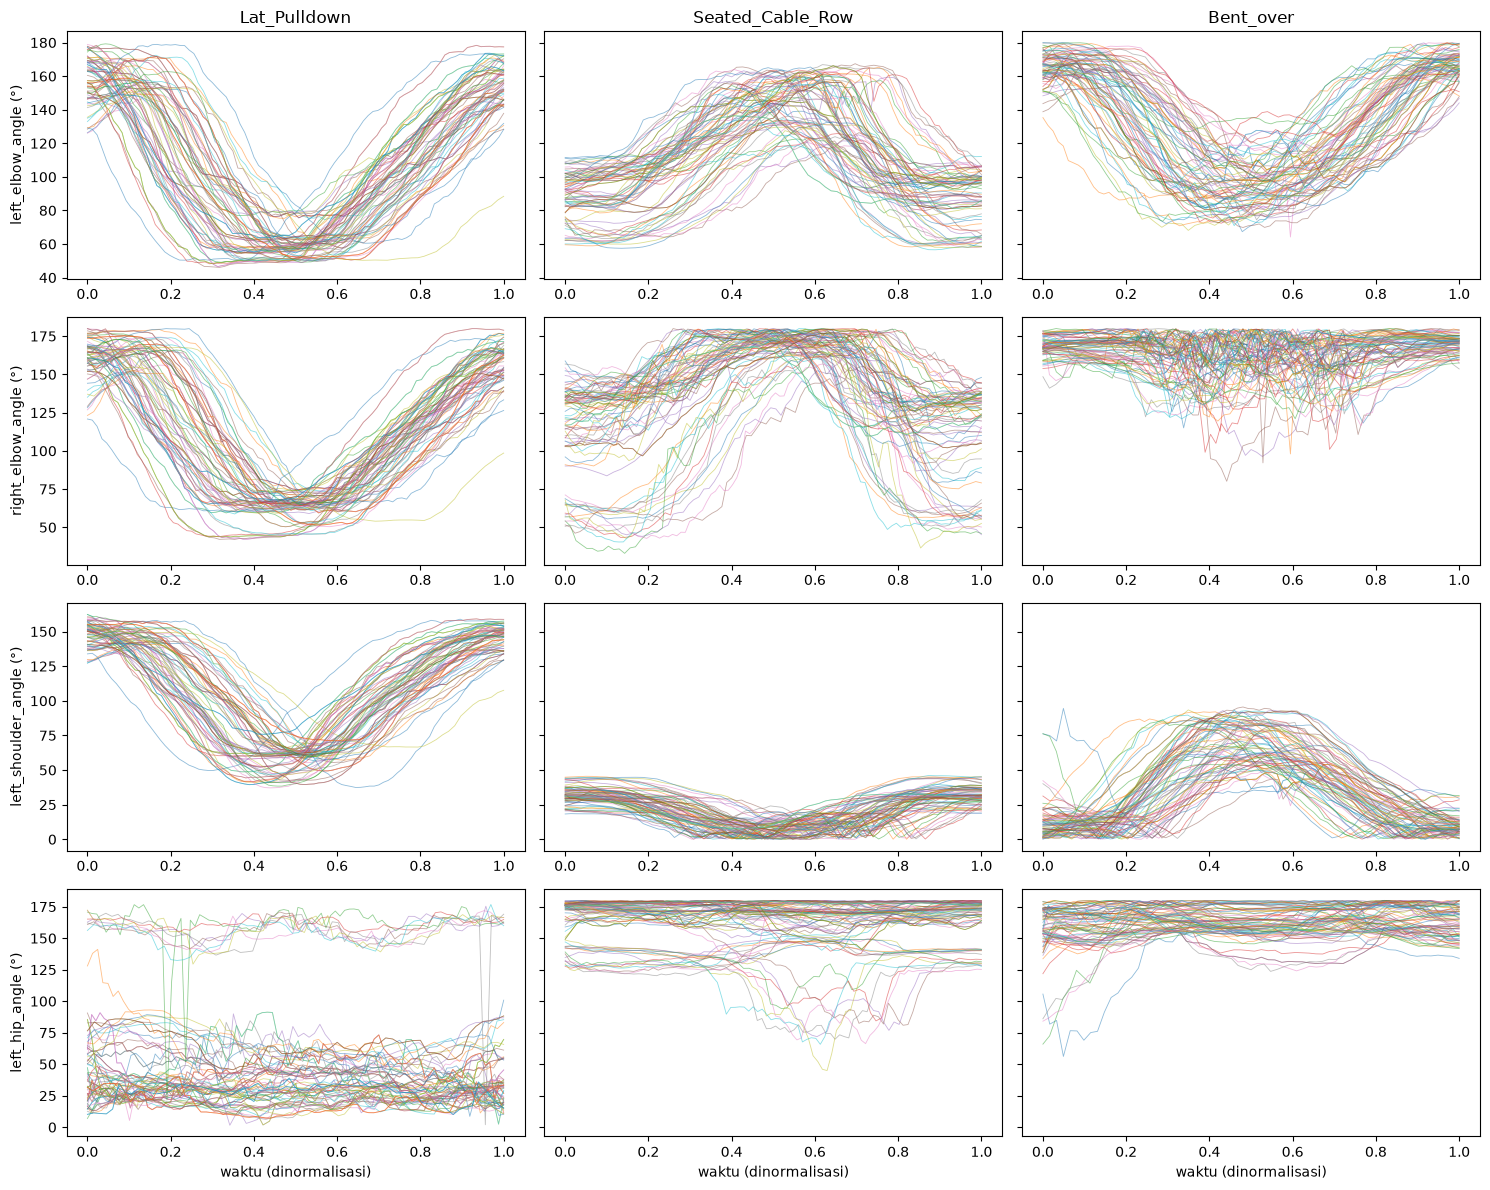

In [19]:
# Cek kewajaran: kurva sudut terhadap waktu (dinormalisasi 0-1) untuk semua video per kelas
plot_angles = ["left_elbow_angle", "right_elbow_angle", "left_shoulder_angle", "left_hip_angle"]
fig, axes = plt.subplots(len(plot_angles), 3, figsize=(15, 3 * len(plot_angles)), sharey="row")
for col, cls in enumerate(CLASS_MAP):
    for _, r in feat_index[(feat_index["class"] == cls) & ~feat_index.excluded].iterrows():
        df = pd.read_csv(FEAT_DIR / r.schemeB_path)
        t = np.linspace(0, 1, len(df))
        for row, ang in enumerate(plot_angles):
            axes[row, col].plot(t, df[ang], lw=0.6, alpha=0.5)
    axes[0, col].set_title(cls)
for row, ang in enumerate(plot_angles):
    axes[row, 0].set_ylabel(f"{ang} (°)")
for ax in axes[-1]:
    ax.set_xlabel("waktu (dinormalisasi)")
plt.tight_layout()
plt.show()

## Tahap 5 – Split Data per Subjek

Split dilakukan **per subjek** (bukan per sampel) supaya tidak ada data leakage: semua video dari satu subjek hanya berada di satu split.

- Subjek 8 dan 9 selalu di split yang sama (`SUBJECT_GROUPS`) karena `lpd8_08` dan `lpd9_08` identik.
- Validasi & uji masing-masing 1 subjek, sisanya latih. Dipilih acak dengan `SEED` tetap.
- Juga dibuat daftar fold **Leave-One-Subject-Out** (LOSO) sebagai evaluasi cadangan.
- Video `excluded` tidak dimasukkan.

> Asumsi: nomor subjek yang sama di ketiga kelas (`lpd_01`, `scr_01`, `bor_01`) diperlakukan sebagai satu subjek. Jika ternyata orang berbeda, split tetap aman dari leakage selama tiap folder subjek tidak terbagi ke beberapa split.

**💡 Penjelasan kode**

- Subjek 8 dan 9 digabung menjadi satu "unit", karena ada file kembar di antara keduanya (supaya tidak bocor antara latih dan uji).
- Dua subjek dipilih acak (dengan `SEED` tetap) sebagai **validasi** dan **uji**, sisanya **latih** (split *holdout*).
- `loso`: daftar fold **Leave-One-Subject-Out**, yaitu setiap unit subjek bergiliran menjadi data uji.
- Semua disimpan ke `data/splits.json` dan dibaca oleh notebook training.

In [20]:
feat_index = pd.read_csv(FEAT_DIR / "index.csv")
usable = feat_index[~feat_index.excluded]
subjects = sorted(int(s) for s in usable.subject.unique())

# Unit split: subjek yang digrup dianggap satu unit
grouped = {s for g in SUBJECT_GROUPS for s in g}
units = [[s] for s in subjects if s not in grouped] + [[s for s in g if s in subjects] for g in SUBJECT_GROUPS]
units = [u for u in units if u]

rng = np.random.default_rng(SEED)
singles = [u for u in units if len(u) == 1]
test_u, val_u = [singles[i] for i in rng.choice(len(singles), 2, replace=False)]
train_subjects = sorted(s for u in units if u not in (test_u, val_u) for s in u)


def videos_of(subs):
    return sorted(usable[usable.subject.isin(subs)].video_id)


splits = {
    "seed": SEED,
    "subject_groups": SUBJECT_GROUPS,
    "holdout": {
        "train": {"subjects": train_subjects, "videos": videos_of(train_subjects)},
        "val": {"subjects": val_u, "videos": videos_of(val_u)},
        "test": {"subjects": test_u, "videos": videos_of(test_u)},
    },
    "loso": [{"test_subjects": u, "test_videos": videos_of(u),
              "train_subjects": sorted(s for s in subjects if s not in u)} for u in units],
}
SPLITS_JSON.write_text(json.dumps(splits, indent=2))

for name in ("train", "val", "test"):
    part = usable[usable.video_id.isin(splits["holdout"][name]["videos"])]
    print(f"{name:5s} subjek {splits['holdout'][name]['subjects']}: {len(part)} video | "
          + ", ".join(f"{c}={n}" for c, n in part.groupby('class').size().items()))
print(f"\nLOSO: {len(splits['loso'])} fold")
print(f"Tersimpan: {SPLITS_JSON}")

train subjek [2, 3, 4, 5, 6, 8, 9, 10]: 192 video | Bent_over=64, Lat_Pulldown=64, Seated_Cable_Row=64
val   subjek [7]: 24 video | Bent_over=8, Lat_Pulldown=8, Seated_Cable_Row=8
test  subjek [1]: 24 video | Bent_over=8, Lat_Pulldown=8, Seated_Cable_Row=8

LOSO: 9 fold
Tersimpan: /Users/albobchai/Desktop/Tugas Akhir - Albert/data/splits.json


## Tahap 6 – Augmentasi Data ×3

Setiap video menghasilkan **2 salinan augmentasi**. Bersama data asli, data menjadi 3× lipat (+200%).

Dua dataset disimpan **terpisah**:

| Dataset | Folder | Isi | Dipakai oleh |
|---|---|---|---|
| Tanpa augmentasi | `data/features/schemeA/` | 240 video asli | `2_training_tanpa_augmentasi.ipynb` |
| Dengan augmentasi | `data/dataset_augmentasi/` | 240 × (`_asli`, `_aug1`, `_aug2`) = 720 file | `3_training_dengan_augmentasi.ipynb` |
 Salinan dibuat untuk **semua** video, karena pada LOSO setiap subjek bergiliran menjadi data latih. Notebook training hanya memakai salinan milik video **latih**; data validasi dan uji selalu asli.

Augmentasi dikerjakan pada koordinat gambar (piksel), sehingga hasilnya disimpan dalam **format yang sama dengan Skema A**, dan kelima skema (A, A', B, C, D) bisa dihitung dari file yang sama.

| Augmentasi | Peluang | Besar | Meniru |
|---|---|---|---|
| Cermin kiri-kanan (gambar dibalik, kiri ↔ kanan ditukar) | 50% | – | orang kidal / kamera di sisi lain |
| Rotasi 2D terhadap tengah pinggul | 50% | ±10° | kamera sedikit miring |
| Skala terhadap tengah pinggul | 50% | ±10% | jarak kamera berbeda |
| Variasi kecepatan (time warping) | 50% | ±20% | orang bergerak lebih cepat/lambat |
| Noise (jitter) | 50% | σ = 0,01 × panjang badan | getaran deteksi MediaPipe |
| Keypoint hilang (diisi interpolasi, seperti Tahap 3) | 30% | 1–2 keypoint anggota badan | sendi tertutup |

Seed tetap (`SEED`), jadi hasilnya selalu sama setiap dijalankan.

**💡 Penjelasan kode**

Pengaturan dan fungsi augmentasi:
- `AUG`: peluang dan besar setiap augmentasi (lihat tabel di atas).
- `MIRROR_PERM`: saat dicerminkan, titik kiri menjadi kanan dan sebaliknya. Contoh: posisi 1 (bahu kiri) ditukar dengan posisi 2 (bahu kanan).
- `load_scheme_a(path)`: membaca CSV Skema A, lalu mengubah x, y, z ke piksel supaya rotasi dan skala tidak terdistorsi.
- `augment(kp, vis, rng)`: menerapkan augmentasi satu per satu. Setiap augmentasi hanya dijalankan jika `rng.random() < peluang` (misalnya 50%). Rotasi dan skala berpusat di **tengah pinggul** tiap frame, supaya badan berputar di tempat. Fungsi mengembalikan keypoints baru, visibility, dan daftar augmentasi yang diterapkan.

In [21]:
AUG_DIR = DATA_DIR / "dataset_augmentasi"
AUG_FACTOR = 3  # 1 asli + 2 salinan augmentasi
AUG = {
    "mirror_p": 0.5,
    "rotate_p": 0.5, "rotate_deg": 10,
    "scale_p": 0.5, "scale_range": 0.1,
    "timewarp_p": 0.5, "timewarp_range": 0.2,
    "jitter_p": 0.5, "jitter_sigma": 0.01,
    "dropout_p": 0.3, "dropout_max_kp": 2,
}
MIN_FRAMES = 30  # panjang minimal setelah variasi kecepatan (= ukuran window)

KP_NAMES = [LANDMARK_NAMES[k] for k in KEYPOINTS]
# Posisi tiap keypoint setelah dicerminkan (kiri <-> kanan), dalam urutan 13 keypoints
MIRROR_PERM = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11]
LIMB_KP = [3, 4, 5, 6, 9, 10, 11, 12]  # siku, pergelangan tangan, lutut, pergelangan kaki
PX = np.array([TARGET_W, TARGET_H, TARGET_W], np.float32)  # z MediaPipe berskala sama dengan x


def load_scheme_a(path):
    # CSV Skema A -> koordinat piksel (T, 13, 3) dan visibility (T, 13)
    arr = pd.read_csv(path).drop(columns="frame").to_numpy(np.float32).reshape(-1, 13, 4)
    return arr[..., :3] * PX, arr[..., 3]


def augment(kp, vis, rng):
    kp, vis, T, applied = kp.copy(), vis.copy(), len(kp), []
    hip = lambda k: k[:, [7, 8], :2].mean(1, keepdims=True)  # tengah pinggul tiap frame (T, 1, 2)
    torso = np.median(np.linalg.norm(kp[:, [1, 2], :2].mean(1) - kp[:, [7, 8], :2].mean(1), axis=-1))

    if rng.random() < AUG["mirror_p"]:
        kp[..., 0] = TARGET_W - kp[..., 0]
        kp, vis = kp[:, MIRROR_PERM], vis[:, MIRROR_PERM]
        applied.append("cermin")
    if rng.random() < AUG["rotate_p"]:
        deg = rng.uniform(-AUG["rotate_deg"], AUG["rotate_deg"])
        t, c = np.radians(deg), hip(kp)
        d = kp[..., :2] - c
        kp[..., 0] = c[..., 0] + d[..., 0] * np.cos(t) - d[..., 1] * np.sin(t)
        kp[..., 1] = c[..., 1] + d[..., 0] * np.sin(t) + d[..., 1] * np.cos(t)
        applied.append(f"rotasi {deg:+.0f}°")
    if rng.random() < AUG["scale_p"]:
        s, c = rng.uniform(1 - AUG["scale_range"], 1 + AUG["scale_range"]), hip(kp)
        kp[..., :2] = c + (kp[..., :2] - c) * s
        kp[..., 2] *= s
        applied.append(f"skala x{s:.2f}")
    if rng.random() < AUG["timewarp_p"]:
        new_T = max(MIN_FRAMES, int(round(T * rng.uniform(1 - AUG["timewarp_range"], 1 + AUG["timewarp_range"]))))
        t_old, t_new = np.linspace(0, 1, T), np.linspace(0, 1, new_T)
        flat = np.concatenate([kp.reshape(T, -1), vis], axis=1)
        flat = np.stack([np.interp(t_new, t_old, flat[:, j]) for j in range(flat.shape[1])], axis=1)
        kp, vis = flat[:, :39].reshape(new_T, 13, 3), flat[:, 39:]
        applied.append(f"kecepatan {T}->{new_T} frame")
        T = new_T
    if rng.random() < AUG["jitter_p"]:
        kp[..., :2] += rng.normal(0, AUG["jitter_sigma"] * torso, kp[..., :2].shape)
        applied.append("noise")
    if rng.random() < AUG["dropout_p"]:
        hidden = []
        for k in rng.choice(LIMB_KP, rng.integers(1, AUG["dropout_max_kp"] + 1), replace=False):
            length = int(T * rng.uniform(0.3, 1.0))
            s = rng.integers(0, T - length + 1)
            a, b = max(s - 1, 0), min(s + length, T - 1)
            w = np.linspace(0, 1, b - a + 1)[:, None]
            kp[a:b + 1, k] = (1 - w) * kp[a, k] + w * kp[b, k]
            hidden.append(KP_NAMES[k])
        applied.append("keypoint hilang: " + ", ".join(hidden))
    return kp.astype(np.float32), vis.astype(np.float32), applied

**💡 Penjelasan kode**

Membuat dataset augmentasi:
- Untuk setiap video: file asli **disalin** menjadi `_asli.csv`, lalu dibuat 2 salinan augmentasi `_aug1.csv` dan `_aug2.csv` dalam format yang sama dengan Skema A (koordinat dikembalikan ke 0–1).
- `np.random.default_rng([SEED, i])`: setiap video punya generator acak sendiri, sehingga hasilnya selalu sama.
- `index.csv` mencatat setiap file beserta augmentasi yang diterapkan (misalnya "cermin; skala x1.05; noise").

In [22]:
import shutil

usable = feat_index[~feat_index.excluded].reset_index(drop=True)
ORIG, AUGMENTED, aug_rows = {}, {}, []
for i, r in enumerate(tqdm(usable.itertuples(), total=len(usable), desc="Augmentasi")):
    kp, vis = load_scheme_a(FEAT_DIR / r.schemeA_path)
    ORIG[r.video_id] = kp
    rng = np.random.default_rng([SEED, i])
    AUGMENTED[r.video_id] = []
    (AUG_DIR / r._2).mkdir(parents=True, exist_ok=True)
    shutil.copy(FEAT_DIR / r.schemeA_path, AUG_DIR / r._2 / f"{r.video_id}_asli.csv")
    aug_rows.append({"video_id": r.video_id, "class": r._2, "subject": r.subject, "salinan": "asli",
                     "path": f"{r._2}/{r.video_id}_asli.csv", "frame_asli": len(kp), "frame_aug": len(kp),
                     "augmentasi": "(data asli)"})
    for n in range(1, AUG_FACTOR):
        kp_aug, vis_aug, applied = augment(kp, vis, rng)
        AUGMENTED[r.video_id].append((kp_aug, applied))
        path = f"{r._2}/{r.video_id}_aug{n}.csv"
        values = np.concatenate([kp_aug / PX, vis_aug[..., None]], axis=-1).reshape(len(kp_aug), -1)
        df = pd.DataFrame(values, columns=COLS_A)
        df.insert(0, "frame", np.arange(len(df)))
        df.to_csv(AUG_DIR / path, index=False, float_format="%.6f")
        aug_rows.append({"video_id": r.video_id, "class": r._2, "subject": r.subject, "salinan": f"aug{n}",
                         "path": path, "frame_asli": len(kp), "frame_aug": len(kp_aug),
                         "augmentasi": "; ".join(applied) or "(tidak ada)"})

aug_index = pd.DataFrame(aug_rows)
aug_index.to_csv(AUG_DIR / "index.csv", index=False)
print(f"Dataset augmentasi: {len(aug_index)} file ({len(usable)} video × {AUG_FACTOR}) -> {AUG_DIR}")
copies = aug_index[aug_index.salinan != "asli"].augmentasi
print("\nFrekuensi tiap augmentasi:")
for name in ["cermin", "rotasi", "skala", "kecepatan", "noise", "keypoint hilang"]:
    print(f"  {name:16s} {copies.str.contains(name).mean():.0%} dari salinan")
aug_index.head(6)

Augmentasi:   0%|          | 0/240 [00:00<?, ?it/s]

Dataset augmentasi: 720 file (240 video × 3) -> /Users/albobchai/Desktop/Tugas Akhir - Albert/data/dataset_augmentasi

Frekuensi tiap augmentasi:
  cermin           51% dari salinan
  rotasi           50% dari salinan
  skala            47% dari salinan
  kecepatan        49% dari salinan
  noise            50% dari salinan
  keypoint hilang  28% dari salinan


,video_id,class,subject,salinan,path,frame_asli,frame_aug,augmentasi
0,lpd1_01,Lat_Pulldown,1,asli,Lat_Pulldown/lpd1_01_asli.csv,89,89,(data asli)
1,lpd1_01,Lat_Pulldown,1,aug1,Lat_Pulldown/lpd1_01_aug1.csv,89,106,rotasi +7°; kecepatan 89->106 frame
2,lpd1_01,Lat_Pulldown,1,aug2,Lat_Pulldown/lpd1_01_aug2.csv,89,89,cermin; rotasi -3°
3,lpd1_02,Lat_Pulldown,1,asli,Lat_Pulldown/lpd1_02_asli.csv,82,82,(data asli)
4,lpd1_02,Lat_Pulldown,1,aug1,Lat_Pulldown/lpd1_02_aug1.csv,82,82,rotasi -2°
5,lpd1_02,Lat_Pulldown,1,aug2,Lat_Pulldown/lpd1_02_aug2.csv,82,82,rotasi +5°; skala x1.00; noise


**💡 Penjelasan kode**

Membandingkan asli dan 2 salinan untuk 3 video contoh. Baris atas: kerangka di frame tengah (terlihat efek cermin, rotasi, skala). Baris bawah: kurva sudut siku kiri terhadap waktu. Pola naik-turunnya harus tetap mirip, karena augmentasi tidak boleh mengubah jenis gerakan.

Catatan: jika sebuah salinan **dicerminkan**, "siku kiri"-nya adalah siku **kanan** orang aslinya, sehingga kurvanya bisa berbeda dari kurva asli (misalnya saat siku kanan asli sering tertutup). Ini wajar. Lihat kolom `augmentasi` di tabel sebelumnya untuk mengetahui salinan mana yang dicerminkan.

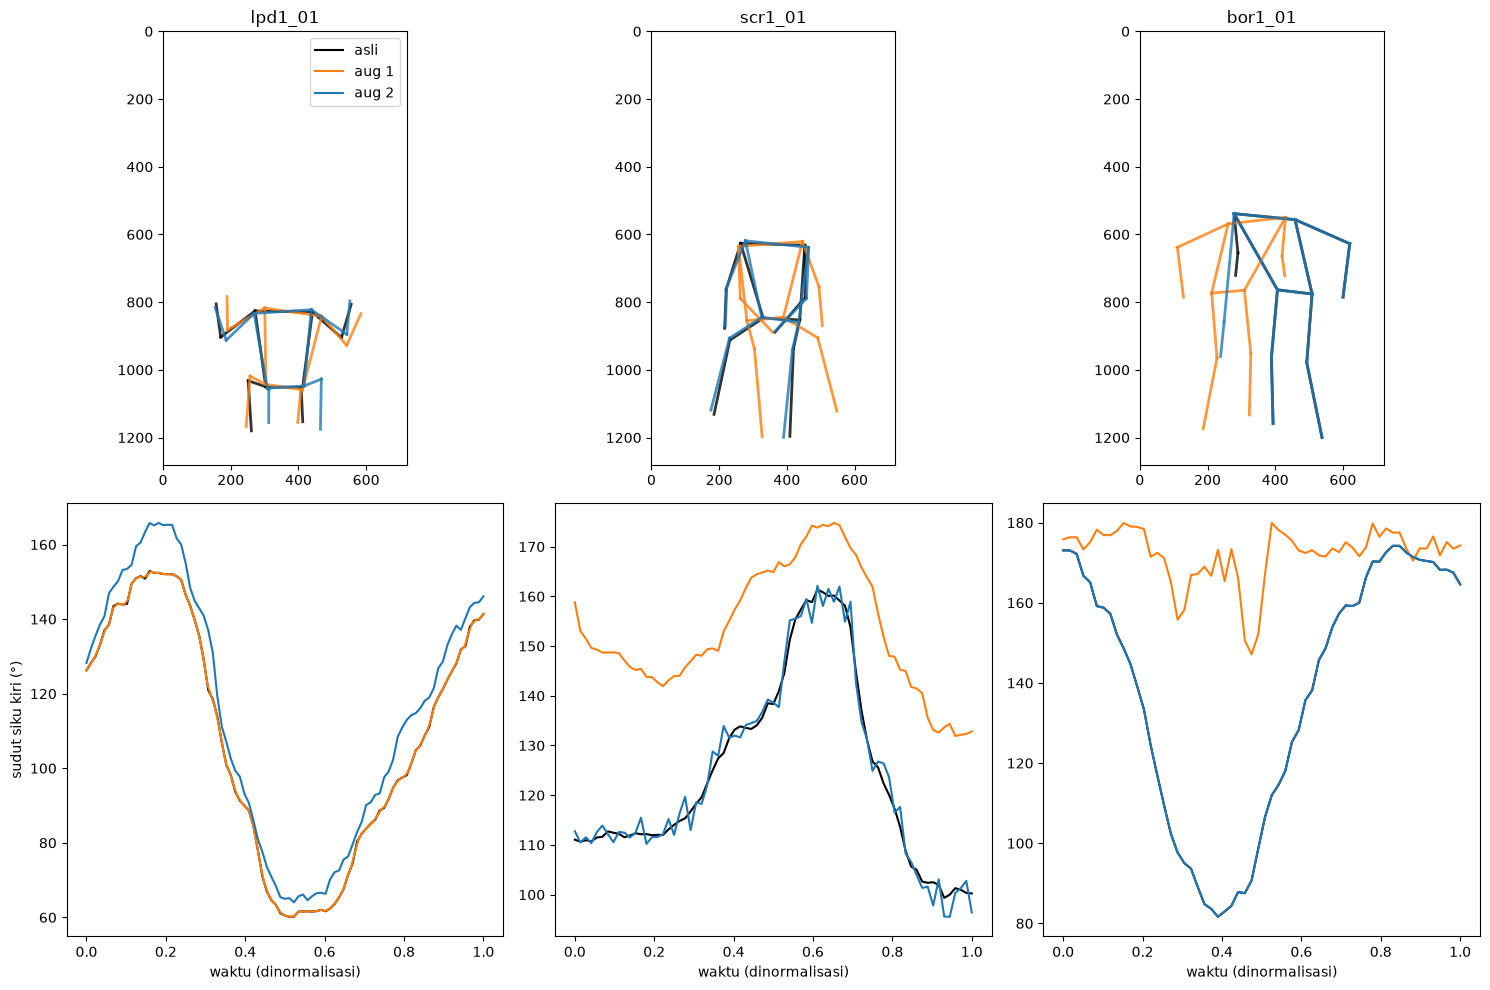

In [23]:
# Contoh: kerangka frame tengah dan kurva sudut siku kiri (asli vs 2 salinan)
EDGES = [(1, 2), (1, 3), (3, 5), (2, 4), (4, 6), (1, 7), (2, 8), (7, 8), (7, 9), (9, 11), (8, 10), (10, 12)]


def elbow_angle(kp):  # siku kiri: bahu kiri (1) - siku kiri (3) - pergelangan kiri (5)
    ba, bc = kp[:, 1, :2] - kp[:, 3, :2], kp[:, 5, :2] - kp[:, 3, :2]
    deg = np.abs(np.degrees(np.arctan2(bc[:, 1], bc[:, 0]) - np.arctan2(ba[:, 1], ba[:, 0]))) % 360
    return np.where(deg > 180, 360 - deg, deg)


examples = ["lpd1_01", "scr1_01", "bor1_01"]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for j, vid in enumerate(examples):
    versions = [("asli", ORIG[vid])] + [(f"aug {n + 1}", k) for n, (k, _) in enumerate(AUGMENTED[vid])]
    for (name, kp), color in zip(versions, ["black", "tab:orange", "tab:blue"]):
        f = kp[len(kp) // 2]
        for a, b in EDGES:
            axes[0, j].plot(f[[a, b], 0], f[[a, b], 1], color=color, lw=2, alpha=0.8)
        axes[0, j].plot([], [], color=color, label=name)
        axes[1, j].plot(np.linspace(0, 1, len(kp)), elbow_angle(kp), color=color, label=name)
    axes[0, j].set(title=vid, xlim=(0, TARGET_W), ylim=(TARGET_H, 0), aspect="equal")
    axes[1, j].set_xlabel("waktu (dinormalisasi)")
axes[1, 0].set_ylabel("sudut siku kiri (°)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### Video kerangka augmentasi

Tiga panel berdampingan: **asli**, **aug 1**, **aug 2**, dalam koordinat gambar, beserta daftar augmentasi yang diterapkan. Dibuat 1 video per subjek per kelas (repetisi `_01`, 30 video). Set `RENDER_ALL = True` untuk semua video.

**💡 Penjelasan kode**

Membuat video kerangka 3 panel (asli, aug 1, aug 2) dengan OpenCV: setiap frame digambar di kanvas putih, lalu ditulis ke mp4 dengan `cv2.VideoWriter`. Jika salinan lebih pendek (variasi kecepatan), panelnya berhenti di frame terakhir.

In [24]:
RENDER_ALL = False
PANEL_W, PANEL_H = TARGET_W // 2, TARGET_H // 2
LEFT = {1, 3, 5, 7, 9, 11}


def put(img, text, org, scale=0.5, color=(30, 30, 30), thick=1):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale, color, thick, cv2.LINE_AA)


def draw_panel(kp_frame, title, notes, t, T):
    img = np.full((PANEL_H, PANEL_W, 3), 255, np.uint8)
    pts = [(int(x / 2), int(y / 2)) for x, y, _ in kp_frame]
    for a, b in EDGES:
        cv2.line(img, pts[a], pts[b], (90, 90, 90), 3, cv2.LINE_AA)
    for k, p in enumerate(pts):
        color = (40, 120, 230) if k in LEFT else ((60, 170, 60) if k else (120, 120, 120))
        cv2.circle(img, p, 6, color, -1, cv2.LINE_AA)
    put(img, title, (10, 24), 0.65, thick=2)
    put(img, f"frame {min(t, T - 1) + 1}/{T}", (10, 46), 0.45)
    for i, line in enumerate(notes):
        put(img, line, (10, PANEL_H - 12 - 18 * (len(notes) - 1 - i)), 0.42, (60, 60, 160))
    return img


def render_aug(video_id):
    cls = usable.loc[usable.video_id == video_id, "class"].iloc[0]
    seqs = [ORIG[video_id]] + [k for k, _ in AUGMENTED[video_id]]
    notes = [["(data asli)"]] + [a or ["(tidak ada)"] for _, a in AUGMENTED[video_id]]
    out = QA_DIR / "augmented" / cls / f"{video_id}_aug.mp4"
    out.parent.mkdir(parents=True, exist_ok=True)
    size = (PANEL_W * len(seqs), PANEL_H + 34)
    for codec in ("avc1", "mp4v"):
        writer = cv2.VideoWriter(str(out), cv2.VideoWriter_fourcc(*codec), TARGET_FPS, size)
        if writer.isOpened():
            break
    for t in range(max(len(s) for s in seqs)):
        panels = [draw_panel(s[min(t, len(s) - 1)], ti, no, t, len(s))
                  for s, ti, no in zip(seqs, ["asli", "aug 1", "aug 2"], notes)]
        frame = np.vstack([np.full((34, size[0], 3), 235, np.uint8), np.hstack(panels)])
        put(frame, f"{cls} | {video_id}  (oranye = sisi kiri, hijau = sisi kanan)", (10, 23), 0.55)
        for x in range(PANEL_W, size[0], PANEL_W):
            cv2.line(frame, (x, 34), (x, size[1]), (200, 200, 200), 1)
        writer.write(frame)
    writer.release()
    return out


targets = usable.video_id.tolist() if RENDER_ALL else usable[usable.video_id.str.endswith("_01")].video_id.tolist()
paths = [render_aug(v) for v in tqdm(targets, desc="Render augmentasi")]
print(f"{len(paths)} video tersimpan di {QA_DIR / 'augmented'}")
display(Video(str(paths[0]), embed=True, width=720))

Render augmentasi:   0%|          | 0/30 [00:00<?, ?it/s]

30 video tersimpan di /Users/albobchai/Desktop/Tugas Akhir - Albert/qa/augmented


## Selesai

Output preprocessing:
- `data/metadata.csv`: data semua video
- `data/keypoints_raw/`, `data/keypoints_clean/`: 33 landmark per frame
- `data/features/schemeA/`, `data/features/schemeB/`, `data/features/index.csv`: fitur per frame per video
- `data/splits.json`: pembagian subjek (holdout + LOSO)
- `data/dataset_augmentasi/<kelas>/<video>_asli.csv`, `_aug1.csv`, `_aug2.csv`, `index.csv`: dataset dengan augmentasi (format Skema A) dan daftar augmentasi yang diterapkan
- `qa/`: grid frame pertama, laporan frame hilang, video marking, video kerangka augmentasi

**Langkah berikutnya:** `2_training_tanpa_augmentasi.ipynb`, lalu `3_training_dengan_augmentasi.ipynb`.